# Non-Contractual Player Churn Analytics & Predictive Pipeline

## 1. Business Understanding & Problem Formulation

What do you think the cost of acquiring a new customer for betting firms is? 
A whooping [$3.9 Billion](https://www.5wpr.com/new/the-gambling-industry-spent-3-9-billion-on-marketing-last-year-here-is-what-the-data-shows/) spread affross different advertisement portfolios to get users to walk through their front door. However, they are all faced with one problem, after filling in the last registration form, getting users to continuously place bets has become another matter entirely. [Data](https://igamingbusiness.com/marketing-affiliates/dot-player-churn-a-real-problem/) suggests only 63% of users active for more than 2 years, and only a third of new users make it to the third year still using betting services.   

The aim of this process is to better understand user behavior through rigorous exploratory analysis and model customer behaviour to predict user churning and possibly reduce churning. 

For subscription based services like Netflix, a churn can be defined as a user cancelling their subscription, usually days in advance with a physical action of clicking an unsubscribe button. 
However, this is not the case for betting companies. A user's churn is usually marked by abandoning an account and ceasing to place bets, which does very little in announcing depature. 

In this study, churn is defined as a player's failure to place a bet or make a deposit for a 45-day target period following a fixed observation cutoff date ($T_{\text{cutoff}}$). This 45-day window represents a valid business compromise, accounting for the fact that active players often pause betting due to normal day-to-day life events or seasonal sports breaks. Using $T_{\text{cutoff}}$ as our target boundary, player behavior leading up to departure is analyzed and the factors driving disengagement are modeled.

The formula is as follows

$$Y_i = \begin{cases} 1 & \text{if } \sum_{t = T_{\text{cutoff}}}^{T_{\text{cutoff}} + 45} \left(\text{Bets}_{i,t} + \text{Deposits}_{i,t}\right) = 0 \\ 0 & \text{otherwise} \end{cases}$$

## Data Understanding

In this phase, the size, memory requirements, cardinality, temporal and logical anomalies are identified. 


In [149]:
# Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import duckdb

In [150]:
# Connecting to DuckDB in-memory database
con = duckdb.connect(database=':memory:')

In [151]:
# Grouping the datasets into a dictionary for easy access
data = {
    'Demographics': 'datasets/SecondSeshData1Demographics.csv',
    'CashGames': 'datasets/SecondSeshData2CashGames.csv',
    'Tournaments': 'datasets/SecondSeshData3Tournaments.csv',
    'Deposits': 'datasets/SecondSeshData4Deposits.csv',
    'Withdrawals': 'datasets/SecondSeshData5Withdrawals.csv',
}

In [152]:
for table_name, file_path in data.items():
    query = f"CREATE OR REPLACE VIEW {table_name} AS SELECT * FROM read_csv_auto('{file_path}')"
    con.execute(query)

print("All CSV views registered successfully in DuckDB!")

All CSV views registered successfully in DuckDB!


In [153]:
# See all registered views
con.execute("SHOW TABLES").fetchdf()

,name
0,CashGames
1,Demographics
2,Deposits
3,Tournaments
4,Withdrawals


In [154]:
# Check shape,number of users, and min/max dates for each table
audit_query = """
SELECT 
    'Demographics' AS table_name,
    COUNT(*) AS total_rows,
    COUNT(DISTINCT UserID) AS unique_users,
    NULL AS min_date,
    NULL AS max_date
FROM Demographics

UNION ALL

SELECT 
    'CashGames',
    COUNT(*),
    COUNT(DISTINCT UserID),
    MIN(CAST(Date AS TIMESTAMP)),
    MAX(CAST(Date AS TIMESTAMP))
FROM CashGames

UNION ALL

SELECT 
    'Tournaments',
    COUNT(*),
    COUNT(DISTINCT UserID),
    MIN(CAST(Date AS TIMESTAMP)),
    MAX(CAST(Date AS TIMESTAMP))
FROM Tournaments

UNION ALL

SELECT 
    'Deposits',
    COUNT(*),
    COUNT(DISTINCT UserID),
    MIN(CAST(ProcessDate AS TIMESTAMP)),
    MAX(CAST(ProcessDate AS TIMESTAMP))
FROM Deposits

UNION ALL

SELECT 
    'Withdrawals',
    COUNT(*),
    COUNT(DISTINCT UserID),
    MIN(CAST(ProcessDate AS TIMESTAMP)),
    MAX(CAST(ProcessDate AS TIMESTAMP))
FROM Withdrawals;
"""

# Run the query and fetch into a Pandas dataframe
audit_results = con.execute(audit_query).fetchdf()
audit_results

,table_name,total_rows,unique_users,min_date,max_date
0,Demographics,5028,5028,NaT,NaT
1,CashGames,51763,4232,2015-02-01,2020-07-28
2,Tournaments,82831,3448,2015-02-01,2021-01-01
3,Deposits,295088,5008,2015-02-01,2020-07-15
4,Withdrawals,32307,1827,2015-02-01,2020-07-15


In [155]:
# Are there transacting users missing from Demographics? If so, how many?
orphaned_users_query = """
-- Check for transaction users missing from Demographics
SELECT 'Orphan CashGame Users' AS issue_type, COUNT(DISTINCT UserID) AS missing_count
FROM CashGames 
WHERE UserID NOT IN (SELECT UserID FROM Demographics)

UNION ALL

SELECT 'Orphan Deposit Users', COUNT(DISTINCT UserID)
FROM Deposits 
WHERE UserID NOT IN (SELECT UserID FROM Demographics)

UNION ALL

SELECT 'Orphan Withdrawal Users', COUNT(DISTINCT UserID)
FROM Withdrawals 
WHERE UserID NOT IN (SELECT UserID FROM Demographics)

UNION ALL

SELECT 'Orphan Tournament Users', COUNT(DISTINCT UserID)
FROM Tournaments 
WHERE UserID NOT IN (SELECT UserID FROM Demographics);
"""
orphaned_users_results = con.execute(orphaned_users_query).fetchdf()
orphaned_users_results

,issue_type,missing_count
0,Orphan CashGame Users,0
1,Orphan Deposit Users,0
2,Orphan Withdrawal Users,0
3,Orphan Tournament Users,0


In [156]:
# Check for missing demographics data
missing_demographics_query = """
SELECT 
    COUNT(*) AS total_rows,
    COUNT(*) - COUNT(UserID) AS missing_user_ids,
    COUNT(*) - COUNT(SystemAgeAsOfReg) AS missing_reg_dates,
    COUNT(*) - COUNT(CountryID) AS missing_countries,
    COUNT(*) - COUNT(Gender) AS missing_genders
FROM Demographics;
"""

missing_demographics_results = con.execute(missing_demographics_query).fetchdf()
missing_demographics_results

,total_rows,missing_user_ids,missing_reg_dates,missing_countries,missing_genders
0,5028,0,0,0,0


In [157]:

# Check for missing transaction data in CashGames
missing_transaction_data_query = """
SELECT 
    'CashGames' AS table_name,
    COUNT(*) AS total_rows,
    COUNT(*) - COUNT(UserID) AS missing_user_ids,
    COUNT(*) - COUNT(Date) AS missing_dates,
    COUNT(*) - COUNT(Windows) AS missing_Windows,
    COUNT(*) - COUNT(StakesC) AS missing_StakesC,
    COUNT(*) - COUNT(WinningsC) AS missing_WinningsC
FROM CashGames
"""
missing_transaction_data = con.execute(missing_transaction_data_query).fetchdf()
missing_transaction_data

,table_name,total_rows,missing_user_ids,missing_dates,missing_Windows,missing_StakesC,missing_WinningsC
0,CashGames,51763,0,0,0,0,0


In [158]:
# Check for missing transaction data in Tournaments
missing_tournament_values = """
SELECT
    'tournament' as table_name,
    COUNT(*) AS total_rows,
    COUNT(*) - COUNT("UserID") AS missingID,
    COUNT(*) - COUNT("Date") AS missingDate,
    COUNT(*) - COUNT("Trnmnts") AS missingTornaments,
    COUNT (*) - COUNT("StakesT") AS missingStakes,
    COUNT (*) - COUNT("WinningsT") as missingWinnings

FROM tournaments

"""

missing_transaction_data = con.execute(missing_tournament_values).fetch_df()
missing_transaction_data

,table_name,total_rows,missingID,missingDate,missingTornaments,missingStakes,missingWinnings
0,tournament,82831,0,0,0,0,0


In [159]:
# Check for missing transaction data in Deposits
missing_Deposit_query = """
SELECT
    'Deposits' as table_name,
    COUNT(*) - COUNT("UserID") AS missingID,
    COUNT(*) - COUNT("DepositID") AS missingDepositID,
    COUNT(*) - COUNT("SummaryDate") AS missingSummaryDate,
    COUNT(*) - COUNT("ProcessDate") AS missingProcessDate,
    COUNT(*) - COUNT("ProcessTime") AS missingProcessTime,
    COUNT(*) - COUNT("PayMeth") AS missingPayMeth,
    COUNT(*) - COUNT("PayMethCat") AS missingPayMethCat,
    COUNT(*) - COUNT("CardType") AS missingCardType,
    COUNT(*) - COUNT("Amount") AS missingAmount,
    COUNT(*) - COUNT("Status") AS missingStatus,
FROM deposits
"""

null_deposits_query = con.execute(missing_Deposit_query).fetch_df()
null_deposits_query

,table_name,missingID,missingDepositID,missingSummaryDate,missingProcessDate,missingProcessTime,missingPayMeth,missingPayMethCat,missingCardType,missingAmount,missingStatus
0,Deposits,0,0,0,0,0,0,0,9920,0,0


In [160]:
# Check for missing transaction data in Withdrawals
missing_withdrawals_query = """
SELECT
    'Deposits' as table_name,
    COUNT (*) AS total,
    COUNT(*) - COUNT("UserID") AS missingID,
    COUNT(*) - COUNT("WithdrawalID") AS missingWithdrawalID,
    COUNT(*) - COUNT("SummaryDate") AS missingSummaryDate,
    COUNT(*) - COUNT("ProcessDate") AS missingProcessDate,
    COUNT(*) - COUNT("ProcessTime") AS missingProcessTime,
    COUNT(*) - COUNT("PayMeth") AS missingPayMeth,
    COUNT(*) - COUNT("PayMethCat") AS missingPayMethCat,
    COUNT(*) - COUNT("CardType") AS missingCardType,
    COUNT(*) - COUNT("Amount") AS missingAmount,
    COUNT(*) - COUNT("Status") AS missingStatus,
FROM withdrawals
"""

missing_withdrawals_data = con.execute(missing_withdrawals_query).fetch_df()
missing_withdrawals_data

,table_name,total,missingID,missingWithdrawalID,missingSummaryDate,missingProcessDate,missingProcessTime,missingPayMeth,missingPayMethCat,missingCardType,missingAmount,missingStatus
0,Deposits,32307,0,0,0,0,0,0,0,1685,0,0


#### Phase 2 Summary & Data Health
- **Referential Integrity & Nulls:** 100% clean primary keys (`UserID`), zero orphan records, nulls documented for feature imputation.
- **Dataset Time Horizon:** 2015-02-01 to 2021-01-01.

## Data Preparation

### 3.1 Data Cleaning & Standardization
This step establishes a clean, standardized data layer across all raw CSV inputs. Primary keys are validated, text values are normalized, date strings are parsed into proper timestamps, and missing financial metrics are filled with zero values to prevent broken joins downstream.

In [161]:
# 3.1 Data Cleaning Layer Setup
cleaning_pipeline_query = """
-- 1. Clean Demographics
CREATE OR REPLACE VIEW Clean_Demographics AS
SELECT 
    CAST(UserID AS BIGINT) AS UserID,
    CAST(SystemAgeAsOfReg AS DATE) AS SystemAgeAsOfReg,
    COALESCE(UPPER(TRIM(CountryID)), 'UNKNOWN') AS CountryID,
    COALESCE(UPPER(TRIM(Gender)), 'U') AS Gender
FROM Demographics
WHERE UserID IS NOT NULL;

-- 2. Clean CashGames
CREATE OR REPLACE VIEW Clean_CashGames AS
SELECT 
    CAST(UserID AS BIGINT) AS UserID,
    CAST(Date AS TIMESTAMP) AS ActivityDate,
    COALESCE(CAST(StakesC AS DOUBLE), 0.0) AS StakesC,
    COALESCE(CAST(WinningsC AS DOUBLE), 0.0) AS WinningsC
FROM CashGames
WHERE UserID IS NOT NULL AND Date IS NOT NULL;

-- 3. Clean Tournaments
CREATE OR REPLACE VIEW Clean_Tournaments AS
SELECT 
    CAST(UserID AS BIGINT) AS UserID,
    CAST(Date AS TIMESTAMP) AS ActivityDate,
    COALESCE(CAST(Trnmnts AS DOUBLE), 0.0) AS Trnmnts,
    COALESCE(CAST(StakesT AS DOUBLE), 0.0) AS StakesT,
    COALESCE(CAST(WinningsT AS DOUBLE), 0.0) AS WinningsT
FROM Tournaments
WHERE UserID IS NOT NULL AND Date IS NOT NULL;

-- 4. Clean Deposits
CREATE OR REPLACE VIEW Clean_Deposits AS
SELECT 
    CAST(UserID AS BIGINT) AS UserID,
    CAST(ProcessDate AS TIMESTAMP) AS DepositDate,
    COALESCE(CAST(Amount AS DOUBLE), 0.0) AS DepositAmount
FROM Deposits
WHERE UserID IS NOT NULL AND ProcessDate IS NOT NULL;

-- 5. Clean Withdrawals
CREATE OR REPLACE VIEW Clean_Withdrawals AS
SELECT 
    CAST(UserID AS BIGINT) AS UserID,
    CAST(ProcessDate AS TIMESTAMP) AS WithdrawalDate,
    COALESCE(CAST(Amount AS DOUBLE), 0.0) AS WithdrawalAmount
FROM Withdrawals
WHERE UserID IS NOT NULL AND ProcessDate IS NOT NULL;
"""

con.execute(cleaning_pipeline_query)
print("Data cleaning layer initialized successfully across all 5 tables.")

Data cleaning layer initialized successfully across all 5 tables.


In [162]:
# 3.2 Temporal Bounds and Churn Label Construction (With Null Imputation)
temporal_target_query = """
-- 1. Anchor timeline bounds to CashGames (2020-07-28)
CREATE OR REPLACE VIEW Global_Timeline_Bounds AS
WITH MaxBound AS (
    SELECT MAX(CAST(ActivityDate AS DATE)) AS T_max FROM Clean_CashGames
)
SELECT 
    T_max,
    T_max - INTERVAL '45 DAYS' AS T_cutoff,
    T_max - INTERVAL '135 DAYS' AS T_active_start -- 90 days prior to T_cutoff
FROM MaxBound;

-- 2. Construct player recency and ground-truth churn labels for active cohort
CREATE OR REPLACE VIEW Player_Temporal_Target AS
WITH Bounds AS (
    SELECT * FROM Global_Timeline_Bounds
),
AllPreActivity AS (
    SELECT UserID, ActivityDate AS dt FROM Clean_CashGames
    UNION ALL
    SELECT UserID, ActivityDate AS dt FROM Clean_Tournaments
    UNION ALL
    SELECT UserID, DepositDate AS dt FROM Clean_Deposits
),
ActiveCohort AS (
    -- Evaluate users active in the 90-day window leading up to T_cutoff (2020-06-13)
    SELECT 
        a.UserID,
        MAX(a.dt) AS LastActivityDate
    FROM AllPreActivity a
    WHERE a.dt <= (SELECT T_cutoff FROM Bounds)
    GROUP BY a.UserID
    HAVING MAX(a.dt) >= (SELECT T_active_start FROM Bounds)
),
AllPostActivity AS (
    -- Numerator: Check for post-cutoff retention across all activity views
    SELECT DISTINCT UserID FROM Clean_CashGames WHERE ActivityDate > (SELECT T_cutoff FROM Bounds)
    UNION
    SELECT DISTINCT UserID FROM Clean_Tournaments WHERE ActivityDate > (SELECT T_cutoff FROM Bounds)
    UNION
    SELECT DISTINCT UserID FROM Clean_Deposits WHERE DepositDate > (SELECT T_cutoff FROM Bounds)
)
SELECT 
    ac.UserID,
    b.T_cutoff,
    ac.LastActivityDate,
    DATEDIFF('day', CAST(ac.LastActivityDate AS DATE), b.T_cutoff) AS days_since_last_activity,
    CASE 
        WHEN post.UserID IS NULL THEN 1 
        ELSE 0 
    END AS churned
FROM ActiveCohort ac
CROSS JOIN Bounds b
LEFT JOIN AllPostActivity post ON ac.UserID = post.UserID;
"""

results = con.execute(temporal_target_query)
con.execute("SELECT * FROM Player_Temporal_Target WHERE UserID = 344298;").fetchdf()

,UserID,T_cutoff,LastActivityDate,days_since_last_activity,churned


In [163]:
con.execute("SELECT * FROM Player_Temporal_Target LIMIT 10;").fetchdf()

,UserID,T_cutoff,LastActivityDate,days_since_last_activity,churned
0,3539,2020-06-13,2020-06-02,11,0
1,3933,2020-06-13,2020-06-12,1,0
2,4486,2020-06-13,2020-04-27,47,1
3,9915,2020-06-13,2020-06-13,0,0
4,15363,2020-06-13,2020-06-12,1,0
5,18393,2020-06-13,2020-05-06,38,1
6,20485,2020-06-13,2020-06-11,2,0
7,22595,2020-06-13,2020-06-13,0,0
8,28837,2020-06-13,2020-06-06,7,1
9,32552,2020-06-13,2020-05-07,37,0


### 3.3 Feature Engineering & Aggregation

To build the predictive feature matrix ($X$), we aggregate player behavioral metrics across two primary domains—cash game activity and deposit transactions—using **strictly pre-cutoff telemetry** ($T \le T_{\text{cutoff}}$) to guarantee zero data leakage.

#### Feature Definitions & Engineering Rationale
* **Recency ($R$):** `days_since_last_bet` and `days_since_last_deposit` compute temporal distance from $T_{\text{cutoff}}$. Unobserved historical activity is explicitly imputed with a sentinel value of `999`.
* **Frequency ($F$):** `total_cash_sessions` (distinct active days) and `total_deposit_count` capture player engagement volume.
* **Monetary ($M$):** `total_stakes`, `total_winnings`, and `total_deposited` record cumulative financial transactions. `net_cash_flow` ($Winnings - Stakes$) models net player profitability.
* **Behavioral Ratios:**
  * `deposit_to_stake_ratio` ($\frac{\text{Deposits}}{\text{Stakes} + 1.0}$): Measures funding efficiency versus wagering activity.
  * `win_rate_ratio` ($\frac{\text{Winnings}}{\text{Stakes} + 1.0}$): Captures player return-on-investment (ROI). A smoothing factor of `+1.0` is added to denominators to prevent division-by-zero errors.
* **Null Handling:** All aggregated fields leverage `COALESCE` to enforce zero-null outputs across missing activity records.

In [164]:
# 3.3 Feature Matrix Construction (Pre-Cutoff Telemetry Only)
feature_matrix_query = """
CREATE OR REPLACE VIEW Player_Feature_Matrix AS
WITH Bounds AS (
    SELECT * FROM Global_Timeline_Bounds
),
-- Aggregate Cash Game Metrics (Pre-Cutoff)
Cash_Stats AS (
    SELECT 
        c.UserID,
        COUNT(DISTINCT CAST(c.ActivityDate AS DATE)) AS total_cash_sessions,
        SUM(c.StakesC) AS total_stakes,
        SUM(c.WinningsC) AS total_winnings
    FROM Clean_CashGames c, Bounds b
    WHERE c.ActivityDate <= b.T_cutoff
    GROUP BY c.UserID
),
-- Aggregate Deposit Metrics (Pre-Cutoff)
Deposit_Stats AS (
    SELECT 
        d.UserID,
        COUNT(*) AS total_deposit_count,
        SUM(d.DepositAmount) AS total_deposited,
        MAX(d.DepositDate) AS LastDepositDate
    FROM Clean_Deposits d, Bounds b
    WHERE d.DepositDate <= b.T_cutoff
    GROUP BY d.UserID
)
-- Main Feature Matrix Join & Imputation
SELECT 
    t.UserID,
    t.days_since_last_activity,
    t.churned,
        
    -- Cash Game Features
    COALESCE(cs.total_cash_sessions, 0) AS total_cash_sessions,
    COALESCE(cs.total_stakes, 0.0) AS total_stakes,
    COALESCE(cs.total_winnings, 0.0) AS total_winnings,
    COALESCE(cs.total_winnings - cs.total_stakes, 0.0) AS net_cash_flow,
        
    -- Deposit Features
    COALESCE(ds.total_deposit_count, 0) AS total_deposit_count,
    COALESCE(ds.total_deposited, 0.0) AS total_deposited,
    COALESCE(
        DATEDIFF('day', CAST(ds.LastDepositDate AS DATE), b.T_cutoff), 
        999
    ) AS days_since_last_deposit,
        
    -- Risk & Velocity Ratios (+1.0 denominator prevents DivisionByZero)
    COALESCE(ds.total_deposited / (cs.total_stakes + 1.0), 0.0) AS deposit_to_stake_ratio,
    COALESCE(cs.total_winnings / (cs.total_stakes + 1.0), 0.0) AS win_rate_ratio
FROM Player_Temporal_Target t
CROSS JOIN Bounds b
LEFT JOIN Cash_Stats cs ON t.UserID = cs.UserID
LEFT JOIN Deposit_Stats ds ON t.UserID = ds.UserID;
"""

con.execute(feature_matrix_query)
print("Player_Feature_Matrix view created successfully.")
con.execute("SELECT * FROM Player_Feature_Matrix LIMIT 5;").fetchdf()

Player_Feature_Matrix view created successfully.


,UserID,days_since_last_activity,churned,total_cash_sessions,total_stakes,total_winnings,net_cash_flow,total_deposit_count,total_deposited,days_since_last_deposit,deposit_to_stake_ratio,win_rate_ratio
0,69225,0,0,4,95.31,60.31,-35.00,883,33218.00,0,344.907071,0.626207
1,9896,0,0,1,3.51,0.00,-3.51,1053,13070.00,0,2898.004435,0.000000
2,18124,0,0,3,212.56,146.22,-66.34,106,2678.64,0,12.542798,0.684679
3,16481,0,0,61,1137.35,956.67,-180.68,605,6565.00,1,5.767119,0.840401
4,6946,0,0,1,1.68,0.84,-0.84,756,14257.80,0,5320.074627,0.313433


In [165]:
con.execute("SELECT * FROM Player_Feature_Matrix LIMIT 5;").fetchdf()

,UserID,days_since_last_activity,churned,total_cash_sessions,total_stakes,total_winnings,net_cash_flow,total_deposit_count,total_deposited,days_since_last_deposit,deposit_to_stake_ratio,win_rate_ratio
0,53737,2,1,0,0.00,0.00,0.00,842,55283.74,2,0.000000,0.000000
1,28837,7,1,3,17.05,11.37,-5.68,256,4075.00,7,225.761773,0.629917
2,22595,0,0,11,2276.12,1870.88,-405.24,471,43478.99,0,19.093851,0.821599
3,9915,0,0,75,2389.61,1970.95,-418.66,1110,12880.00,0,5.387746,0.824455
4,38158,25,0,140,19368.28,17910.73,-1457.55,487,15659.52,25,0.808472,0.924698


### 3.4 Final Dataset Export & Quality Audit

Before transitioning to Phase 4 (Modeling), we extract `Player_Feature_Matrix` into Pandas, audit missing values, verify target distribution class imbalance, and export the sanitized feature set to disk.

In [166]:
import pandas as pd

# 1. High-speed direct export using DuckDB engine (bypasses PyArrow/Pandas extension bugs)
con.execute("""
    COPY Player_Feature_Matrix 
    TO 'igaming_churn_prepared_dataset.parquet' (FORMAT PARQUET);
""")
print("Success: Final modeling dataset exported directly to 'igaming_churn_prepared_dataset.parquet'.")

# 2. Load into Pandas for verification
df_model = con.execute("SELECT * FROM Player_Feature_Matrix;").fetchdf()

# 3. Final Schema and Summary Verification
print("\n--- DATASET INTEGRITY CHECK ---")
print(f"Total Active Cohort Players: {len(df_model):,}")
print(f"Total Columns: {len(df_model.columns)}")
print(f"Total Null Values Across Matrix: {df_model.isnull().sum().sum()}")

churn_counts = df_model['churned'].value_counts()
churn_pct = df_model['churned'].value_counts(normalize=True) * 100

print("\n--- CHURN TARGET DISTRIBUTION (Y) ---")
print(f"Retained (0): {churn_counts.get(0, 0):,} ({churn_pct.get(0, 0):.2f}%)")
print(f"Churned  (1): {churn_counts.get(1, 0):,} ({churn_pct.get(1, 0):.2f}%)")

df_model.head()

Success: Final modeling dataset exported directly to 'igaming_churn_prepared_dataset.parquet'.

--- DATASET INTEGRITY CHECK ---
Total Active Cohort Players: 409
Total Columns: 12
Total Null Values Across Matrix: 0

--- CHURN TARGET DISTRIBUTION (Y) ---
Retained (0): 233 (56.97%)
Churned  (1): 176 (43.03%)


,UserID,days_since_last_activity,churned,total_cash_sessions,total_stakes,total_winnings,net_cash_flow,total_deposit_count,total_deposited,days_since_last_deposit,deposit_to_stake_ratio,win_rate_ratio
0,64938,3,0,0,0.00,0.00,0.00,402,8594.00,3,0.000000,0.000000
1,33395,0,0,2,267.30,274.41,7.11,761,56671.30,0,211.223630,1.022773
2,35311,0,0,525,1655.64,1609.73,-45.91,58,605.00,73,0.365197,0.971684
3,13996,1,0,0,0.00,0.00,0.00,2155,80035.00,1,0.000000,0.000000
4,49233,0,0,6,287.36,241.76,-45.60,1246,67555.75,0,234.275732,0.838396


In [167]:
# Diagnostic Query: Check Activity Distribution over time
con.execute("""
SELECT 
    MIN(CAST(ActivityDate AS DATE)) AS EarliestDate,
    MAX(CAST(ActivityDate AS DATE)) AS LatestDate,
    COUNT(DISTINCT UserID) AS TotalUsers,
    COUNT(*) AS TotalTransactions
FROM Clean_CashGames;
""").fetchdf()

,EarliestDate,LatestDate,TotalUsers,TotalTransactions
0,2015-02-01,2020-07-28,4232,51763


In [168]:
con.execute("""
SELECT 
    STRFTIME(CAST(ActivityDate AS DATE), '%Y-%m') AS YearMonth,
    COUNT(DISTINCT UserID) AS ActiveUsers,
    COUNT(*) AS TotalBets
FROM Clean_CashGames
GROUP BY YearMonth
ORDER BY YearMonth ASC;
""").fetchdf()

,YearMonth,ActiveUsers,TotalBets
0,2015-02,2686,8546
1,2015-03,1536,7439
2,2015-04,729,3767
3,2015-05,524,2765
4,2015-06,384,1963
...,...,...,...
61,2020-03,57,168
62,2020-04,45,150
63,2020-05,47,130
64,2020-06,30,81


In [169]:
import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

# 1. Define Features & Target (drop identifier columns)
drop_cols = ['UserID', 'churned']
X = df_model.drop(columns=[c for c in drop_cols if c in df_model.columns])
y = df_model['churned']

print(f"Feature Matrix Shape: {X.shape}")
print(f"Features: {list(X.columns)}\n")

# 2. Define Baseline Models & Pipelines
models = {
    "Logistic Regression": Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(random_state=42, max_iter=1000))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, 
        random_state=42, 
        class_weight='balanced'
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=100, 
        learning_rate=0.05, 
        random_state=42, 
        verbose=-1
    )
}

# 3. Stratified 5-Fold Cross-Validation Setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

results = []

for name, model in models.items():
    cv_results = cross_validate(
        model, X, y, cv=cv, scoring=scoring, n_jobs=-1
    )
    
    results.append({
        'Model': name,
        'ROC-AUC': np.mean(cv_results['test_roc_auc']),
        'F1-Score': np.mean(cv_results['test_f1']),
        'Recall (Churn)': np.mean(cv_results['test_recall']),
        'Precision': np.mean(cv_results['test_precision']),
        'Accuracy': np.mean(cv_results['test_accuracy'])
    })

# 4. Display Performance Summary
df_results = pd.DataFrame(results).sort_values(by='ROC-AUC', ascending=False)
print("=== BASELINE MODEL PERFORMANCE (5-FOLD CV) ===")
print(df_results.to_string(index=False))

Feature Matrix Shape: (409, 10)
Features: ['days_since_last_activity', 'total_cash_sessions', 'total_stakes', 'total_winnings', 'net_cash_flow', 'total_deposit_count', 'total_deposited', 'days_since_last_deposit', 'deposit_to_stake_ratio', 'win_rate_ratio']

=== BASELINE MODEL PERFORMANCE (5-FOLD CV) ===
              Model  ROC-AUC  F1-Score  Recall (Churn)  Precision  Accuracy
      Random Forest 0.828748  0.689858        0.681746   0.704183  0.738272
           LightGBM 0.816189  0.685430        0.670952   0.708011  0.738272
Logistic Regression 0.815296  0.669231        0.585397   0.788533  0.753026


=== RANDOM FOREST FEATURE IMPORTANCES ===
                 Feature  RF_Importance
days_since_last_activity       0.275438
 days_since_last_deposit       0.164500
     total_deposit_count       0.110693
         total_deposited       0.103147
  deposit_to_stake_ratio       0.068559
          total_winnings       0.061059
          win_rate_ratio       0.058440
            total_stakes       0.054847
           net_cash_flow       0.054373
     total_cash_sessions       0.048946


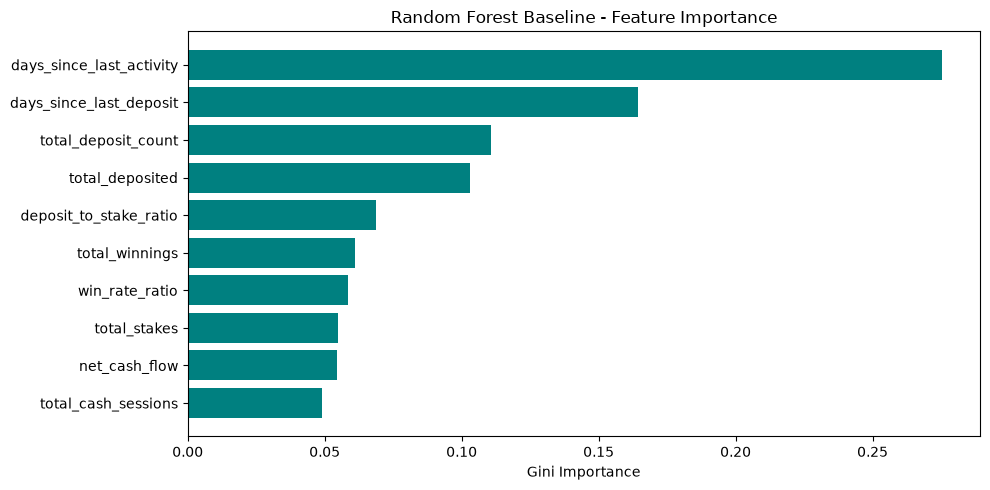

In [170]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Fit Random Forest on full cohort
rf_model = models["Random Forest"]
rf_model.fit(X, y)

# 2. Extract Feature Importances
importances = pd.DataFrame({
    'Feature': X.columns,
    'RF_Importance': rf_model.feature_importances_
}).sort_values(by='RF_Importance', ascending=False)

print("=== RANDOM FOREST FEATURE IMPORTANCES ===")
print(importances.to_string(index=False))

# 3. Plot Top Drivers
plt.figure(figsize=(10, 5))
plt.barh(importances['Feature'][::-1], importances['RF_Importance'][::-1], color='teal')
plt.xlabel("Gini Importance")
plt.title("Random Forest Baseline - Feature Importance")
plt.tight_layout()
plt.show()

/home/dennis/Documents/Data Science/Betting/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


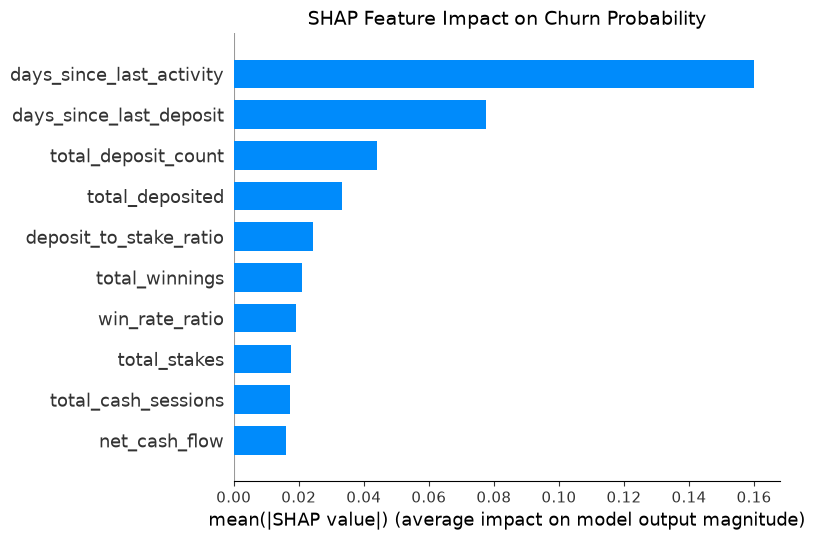

In [171]:
import shap
import matplotlib.pyplot as plt

# 1. Compute SHAP Values for Random Forest Baseline
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X)

# Handle multi-class / binary indexing output for SHAP
if isinstance(shap_values, list):
    shap_vals_churn = shap_values[1] # Target = Churned (1)
else:
    shap_vals_churn = shap_values[:, :, 1] if len(shap_values.shape) == 3 else shap_values

# 2. Plot SHAP Summary (Beeswarm)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_churn, X, plot_type="bar", show=False)
plt.title("SHAP Feature Impact on Churn Probability", fontsize=14)
plt.tight_layout()
plt.show()

In [172]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

# 1. Define Features & Target - EXCLUDING ALL RECENCY/DATE-BASED DRIVERS!
recency_cols = ['days_since_last_activity', 'days_since_last_deposit']
drop_cols = ['UserID', 'churned'] + recency_cols

X_no_recency = df_model.drop(columns=[c for c in drop_cols if c in df_model.columns])
y = df_model['churned']

print("--- TESTING RE-BALANCED MODEL (NO RECENCY) ---")
print(f"Feature Matrix Shape: {X_no_recency.shape}")
print(f"Non-Recency Features: {list(X_no_recency.columns)}\n")

# 2. Define Pipelines
models_no_rec = {
    "Random Forest (No Recency)": RandomForestClassifier(
        n_estimators=100, 
        random_state=42, 
        class_weight='balanced'
    ),
    "LightGBM (No Recency)": LGBMClassifier(
        n_estimators=100, 
        learning_rate=0.05, 
        random_state=42, 
        verbose=-1
    )
}

# 3. Stratified 5-Fold Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

results_no_rec = []

for name, model in models_no_rec.items():
    cv_results = cross_validate(
        model, X_no_recency, y, cv=cv, scoring=scoring, n_jobs=-1
    )
    
    results_no_rec.append({
        'Model': name,
        'ROC-AUC': np.mean(cv_results['test_roc_auc']),
        'F1-Score': np.mean(cv_results['test_f1']),
        'Recall (Churn)': np.mean(cv_results['test_recall']),
        'Precision': np.mean(cv_results['test_precision']),
        'Accuracy': np.mean(cv_results['test_accuracy'])
    })

df_results_no_rec = pd.DataFrame(results_no_rec)
print("=== PERFORMANCE WITHOUT RECENCY DRIVERS ===")
print(df_results_no_rec.to_string(index=False))

--- TESTING RE-BALANCED MODEL (NO RECENCY) ---
Feature Matrix Shape: (409, 8)
Non-Recency Features: ['total_cash_sessions', 'total_stakes', 'total_winnings', 'net_cash_flow', 'total_deposit_count', 'total_deposited', 'deposit_to_stake_ratio', 'win_rate_ratio']

=== PERFORMANCE WITHOUT RECENCY DRIVERS ===
                     Model  ROC-AUC  F1-Score  Recall (Churn)  Precision  Accuracy
Random Forest (No Recency) 0.598159  0.500464        0.488413   0.516110  0.581783
     LightGBM (No Recency) 0.621960  0.505094        0.477143   0.539409  0.601295


In [173]:
recent_query = """
CREATE OR REPLACE VIEW Player_Feature_Matrix_V2 AS
WITH Bounds AS (
    SELECT * FROM Global_Timeline_Bounds
),
-- Pre-cutoff activity overall vs. recent 30-day momentum window
Cash_Stats AS (
    SELECT 
        c.UserID,
        COUNT(DISTINCT CAST(c.ActivityDate AS DATE)) AS total_cash_sessions,
        SUM(c.StakesC) AS total_stakes,
        SUM(c.WinningsC) AS total_winnings,
        -- Recent 30-day momentum window (Pre-Cutoff)
        SUM(CASE WHEN c.ActivityDate >= (b.T_cutoff - INTERVAL '30 DAYS') THEN c.StakesC ELSE 0 END) AS stakes_last_30d,
        COUNT(DISTINCT CASE WHEN c.ActivityDate >= (b.T_cutoff - INTERVAL '30 DAYS') THEN CAST(c.ActivityDate AS DATE) END) AS sessions_last_30d
    FROM Clean_CashGames c, Bounds b
    WHERE c.ActivityDate <= b.T_cutoff
    GROUP BY c.UserID
),
Deposit_Stats AS (
    SELECT 
        d.UserID,
        COUNT(*) AS total_deposit_count,
        SUM(d.DepositAmount) AS total_deposited,
        MAX(d.DepositDate) AS LastDepositDate,
        -- Recent 30-day deposit momentum window
        SUM(CASE WHEN d.DepositDate >= (b.T_cutoff - INTERVAL '30 DAYS') THEN d.DepositAmount ELSE 0 END) AS deposits_last_30d,
        COUNT(CASE WHEN d.DepositDate >= (b.T_cutoff - INTERVAL '30 DAYS') THEN 1 END) AS deposit_count_last_30d
    FROM Clean_Deposits d, Bounds b
    WHERE d.DepositDate <= b.T_cutoff
    GROUP BY d.UserID
)
SELECT 
    t.UserID,
    t.churned,
        
    -- Base Financial & Volume Metrics
    COALESCE(cs.total_cash_sessions, 0) AS total_cash_sessions,
    COALESCE(cs.total_stakes, 0.0) AS total_stakes,
    COALESCE(cs.total_winnings, 0.0) AS total_winnings,
    COALESCE(cs.total_winnings - cs.total_stakes, 0.0) AS net_cash_flow,
    COALESCE(ds.total_deposit_count, 0) AS total_deposit_count,
    COALESCE(ds.total_deposited, 0.0) AS total_deposited,
        
    -- Behavioral Ratios
    COALESCE(ds.total_deposited / (cs.total_stakes + 1.0), 0.0) AS deposit_to_stake_ratio,
    COALESCE(cs.total_winnings / (cs.total_stakes + 1.0), 0.0) AS win_rate_ratio,
    
    -- Velocity / Momentum Ratios (30-day activity vs. Lifetime baseline)
    COALESCE(cs.stakes_last_30d / (cs.total_stakes + 1.0), 0.0) AS stake_velocity_30d,
    COALESCE(cs.sessions_last_30d / (cs.total_cash_sessions + 1.0), 0.0) AS session_velocity_30d,
    COALESCE(ds.deposits_last_30d / (ds.total_deposited + 1.0), 0.0) AS deposit_velocity_30d,
    COALESCE(ds.deposit_count_last_30d / (ds.total_deposit_count + 1.0), 0.0) AS deposit_freq_velocity_30d
FROM Player_Temporal_Target t
CROSS JOIN Bounds b
LEFT JOIN Cash_Stats cs ON t.UserID = cs.UserID
LEFT JOIN Deposit_Stats ds ON t.UserID = ds.UserID;
"""
results = con.execute(recent_query)
con.execute("SELECT * FROM Player_Feature_Matrix_V2 LIMIT 5;").fetchdf() 


,UserID,churned,total_cash_sessions,total_stakes,total_winnings,net_cash_flow,total_deposit_count,total_deposited,deposit_to_stake_ratio,win_rate_ratio,stake_velocity_30d,session_velocity_30d,deposit_velocity_30d,deposit_freq_velocity_30d
0,53737,1,0,0.00,0.00,0.00,842,55283.74,0.000000,0.000000,0.000000,0.000000,0.079443,0.052195
1,28837,1,3,17.05,11.37,-5.68,256,4075.00,225.761773,0.629917,0.000000,0.000000,0.024534,0.038911
2,22595,0,11,2276.12,1870.88,-405.24,471,43478.99,19.093851,0.821599,0.000000,0.000000,0.011500,0.010593
3,9915,0,75,2389.61,1970.95,-418.66,1110,12880.00,5.387746,0.824455,0.000000,0.000000,0.045028,0.005401
4,38158,0,140,19368.28,17910.73,-1457.55,487,15659.52,0.808472,0.924698,0.036303,0.021277,0.030650,0.014344


In [174]:
import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

# 1. Fetch V2 Matrix directly into Pandas
df_v2 = con.execute("SELECT * FROM Player_Feature_Matrix_V2;").fetchdf()

X_v2 = df_v2.drop(columns=['UserID', 'churned'])
y_v2 = df_v2['churned']

print("--- TESTING VELOCITY-ENHANCED MODEL (V2 - NO RAW RECENCY) ---")
print(f"Feature Matrix Shape: {X_v2.shape}")
print(f"Features: {list(X_v2.columns)}\n")

# 2. Define Pipelines
models_v2 = {
    "Random Forest (V2 Velocity)": RandomForestClassifier(
        n_estimators=100, 
        random_state=42, 
        class_weight='balanced'
    ),
    "LightGBM (V2 Velocity)": LGBMClassifier(
        n_estimators=100, 
        learning_rate=0.05, 
        random_state=42, 
        verbose=-1
    )
}

# 3. Stratified 5-Fold Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

results_v2 = []

for name, model in models_v2.items():
    cv_results = cross_validate(
        model, X_v2, y_v2, cv=cv, scoring=scoring, n_jobs=-1
    )
    
    results_v2.append({
        'Model': name,
        'ROC-AUC': np.mean(cv_results['test_roc_auc']),
        'F1-Score': np.mean(cv_results['test_f1']),
        'Recall (Churn)': np.mean(cv_results['test_recall']),
        'Precision': np.mean(cv_results['test_precision']),
        'Accuracy': np.mean(cv_results['test_accuracy'])
    })

df_results_v2 = pd.DataFrame(results_v2)
print("=== PERFORMANCE WITH VELOCITY & MOMENTUM FEATURES ===")
print(df_results_v2.to_string(index=False))

--- TESTING VELOCITY-ENHANCED MODEL (V2 - NO RAW RECENCY) ---
Feature Matrix Shape: (409, 12)
Features: ['total_cash_sessions', 'total_stakes', 'total_winnings', 'net_cash_flow', 'total_deposit_count', 'total_deposited', 'deposit_to_stake_ratio', 'win_rate_ratio', 'stake_velocity_30d', 'session_velocity_30d', 'deposit_velocity_30d', 'deposit_freq_velocity_30d']

=== PERFORMANCE WITH VELOCITY & MOMENTUM FEATURES ===
                      Model  ROC-AUC  F1-Score  Recall (Churn)  Precision  Accuracy
Random Forest (V2 Velocity) 0.722689  0.620731        0.625238   0.638480  0.674706
     LightGBM (V2 Velocity) 0.721533  0.609889        0.619365   0.635879  0.669708


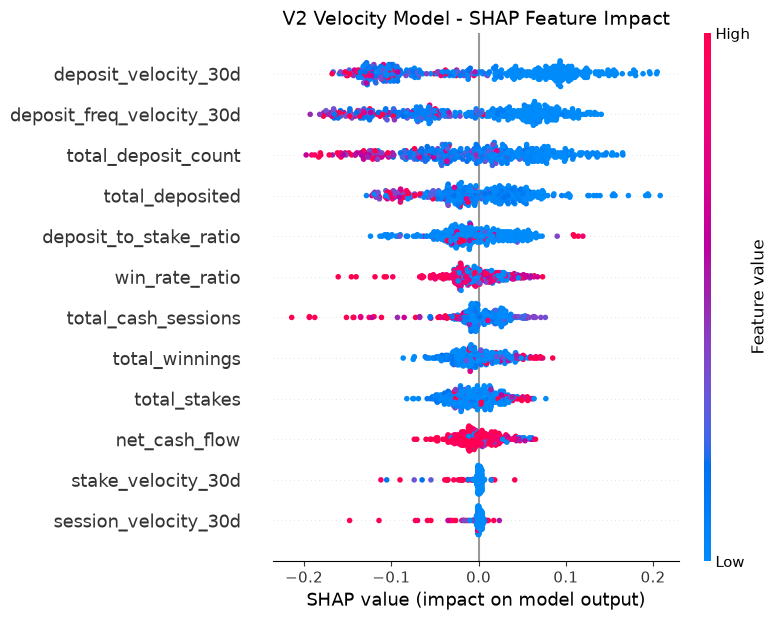

In [175]:
import shap
import matplotlib.pyplot as plt

# 1. Fit Random Forest V2 on full dataset
rf_v2 = models_v2["Random Forest (V2 Velocity)"]
rf_v2.fit(X_v2, y_v2)

# 2. Compute SHAP Values
explainer_v2 = shap.TreeExplainer(rf_v2)
shap_values_v2 = explainer_v2.shap_values(X_v2)

# Handle output structure for binary target
if isinstance(shap_values_v2, list):
    shap_vals = shap_values_v2[1] # Target = Churned (1)
else:
    shap_vals = shap_values_v2[:, :, 1] if len(shap_values_v2.shape) == 3 else shap_values_v2

# 3. Summary Beeswarm Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals, X_v2, show=False)
plt.title("V2 Velocity Model - SHAP Feature Impact", fontsize=14)
plt.tight_layout()
plt.show()

In [176]:
shap_vals

array([[-0.00979148, -0.00545198, -0.01262294, ..., -0.00152733,
        -0.14222389, -0.1655465 ],
       [-0.00463947, -0.01243329, -0.01930818, ..., -0.00136908,
        -0.0978693 , -0.08176869],
       [-0.19382338, -0.05548118, -0.04199733, ...,  0.00166168,
         0.03087089,  0.02523364],
       ...,
       [ 0.03234784,  0.0275129 ,  0.01574932, ...,  0.00078395,
        -0.02518363, -0.04674855],
       [ 0.02150893,  0.0248117 ,  0.01500819, ...,  0.0025228 ,
         0.01973108,  0.0223344 ],
       [ 0.02576387,  0.00961306,  0.00728155, ...,  0.00425881,
         0.08471581,  0.06002494]], shape=(409, 12))